# 重磁位场数据处理 —— 课堂演示

**数据**：`data/brtpgrd.gxf` —— 美国 Colorado 地区航磁异常（Geosoft GXF 格式）

**内容**：
- 位场数据的预处理（去趋势、平滑、空值填充）
- 方向导数与垂直导数
- 边界识别算子（HGM / Tilt / 总梯度 / 局部波数 / TAHG）
- 向上延拓与区域-局部分离
- 每个算子的算法原理、公式与结果解读

**演示库**：`interpies_lite`（https://github.com/xyt556/interpies-lite）

---


## 1. 数据介绍

航磁测量通过飞机搭载磁力仪，测量地磁场总强度的空间变化。地下岩石磁性差异（如玄武岩 vs 沉积岩）会在地表形成可观测的磁异常。

| 项目 | 值 |
| --- | --- |
| 文件 | `brtpgrd.gxf` |
| 尺寸 | 707 行 × 629 列 |
| 像元大小 | 50 m × 50 m |
| 坐标系 | NAD27 / UTM zone 13N |
| 异常范围 | 约 -758 ~ +301 nT |
| 测量高度 | 航高（约几十米） |

磁异常图本质上是一个二维标量场 $T(x,y)$，我们的任务是从这个标量场中**分离区域背景、突出地质体边界、估算场源深度**。


## 2. 环境准备

In [35]:
import sys
from pathlib import Path

# 自动定位 interpies_lite 包与项目根目录
for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / 'interpies_lite').exists():
        sys.path.insert(0, str(_p))
        PROJECT_ROOT = _p
        break
DATA_DIR = PROJECT_ROOT / 'data'

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# 中文字体
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

import interpies_lite as ip
print('interpies_lite version:', ip.__version__)


interpies_lite version: 0.1.0


## 3. 加载数据并查看

In [36]:
g = ip.open(str(DATA_DIR / 'brtpgrd.gxf'))
g.info()


Grid: brtpgrd
  file      : f:\遥感开发技术\interpies\data\brtpgrd.gxf
  shape     : 707 rows x 629 cols
  cellsize  : 50.0 x 50.0
  extent    : [440775.0, 472225.0, 4118575.0, 4153925.0]
  crs       : PROJCS["NAD27 / UTM zone 13N",GEOGCS["NAD27",DATUM["NAD27",SPHEROID["NAD27",6378206.4,294.978698235484]],PRIMEM["unnamed",0],UNIT["degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-105],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["m",1],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
  min/max   : -758.810 / 301.310
  mean/std  : -417.534 +/- 109.339


### 原始数据成图

下面这张图是我们后续所有处理的起点。图上的"色带"对应磁异常高低，浅色（暖色）是正异常（磁性体），深色（冷色）是负异常。


<Axes: title={'center': '原始航磁异常 T(x,y)'}, xlabel='Easting', ylabel='Northing'>

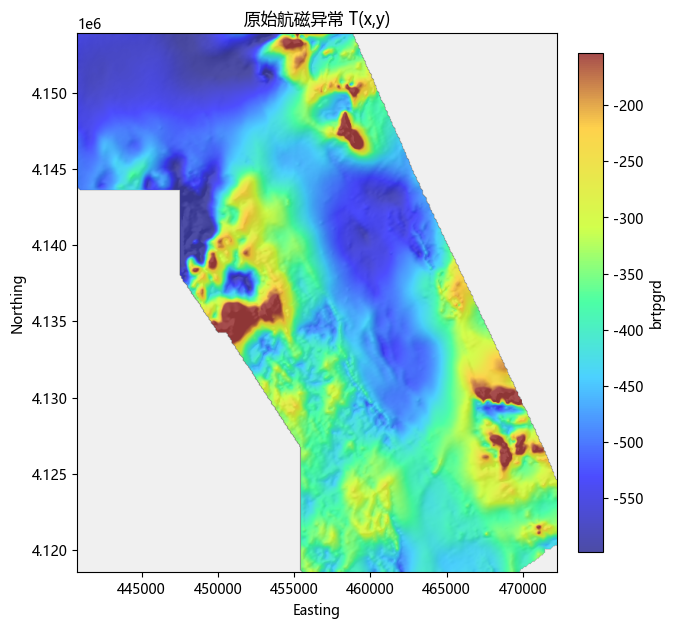

In [37]:
g.show(figsize=(7, 7), cmap='geosoft', hs=True, title='原始航磁异常 T(x,y)')


---

## 4. 预处理

### 4.1 为什么需要预处理？

原始磁测数据通常包含三类不需要的成分：
1. **测量噪声**：仪器抖动、飞行姿态变化 → 高频随机噪声
2. **区域趋势**：深部大尺度地质体或日变校正残差 → 缓变的多项式曲面
3. **边缘空区**：测区边界外无数据 → `nodata` 像元，傅里叶变换会把它当成"信号"

### 4.2 三个预处理操作

| 操作 | 算法 | 作用 |
| --- | --- | --- |
| `fill_nodata()` | 最近邻/距离加权插值 | 把边缘空区填上合理值，避免傅里叶变换产生环状伪影 |
| `detrend(degree=1)` | 最小二乘拟合一次多项式 $a+bx+cy$ 并扣除 | 去除线性区域背景，突出局部异常 |
| `smooth(win=5)` | Savitzky-Golay 多项式平滑 | 压制高频噪声，同时保留异常的峰值位置 |

> **Savitzky-Golay 平滑原理**：在一个滑动窗口内对数据做多项式最小二乘拟合，用拟合值代替原始值。它比移动平均更能保留峰的高度和位置，因为拟合是"多项式形状约束"的。


e:\venv\venv312\Lib\site-packages\interpies_lite\transforms.py:42: RuntimeWarning: Mean of empty slice
  lambda v: np.nanmean(v),


Grid: brtpgrd_filled_detrend1_smooth
  file      : f:\遥感开发技术\interpies\data\brtpgrd.gxf
  shape     : 707 rows x 629 cols
  cellsize  : 50.0 x 50.0
  extent    : [440775.0, 472225.0, 4118575.0, 4153925.0]
  crs       : PROJCS["NAD27 / UTM zone 13N",GEOGCS["NAD27",DATUM["NAD27",SPHEROID["NAD27",6378206.4,294.978698235484]],PRIMEM["unnamed",0],UNIT["degree",0.0174532925199433]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-105],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["m",1],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
  min/max   : -512.337 / 521.731
  mean/std  : -100.694 +/- 115.150


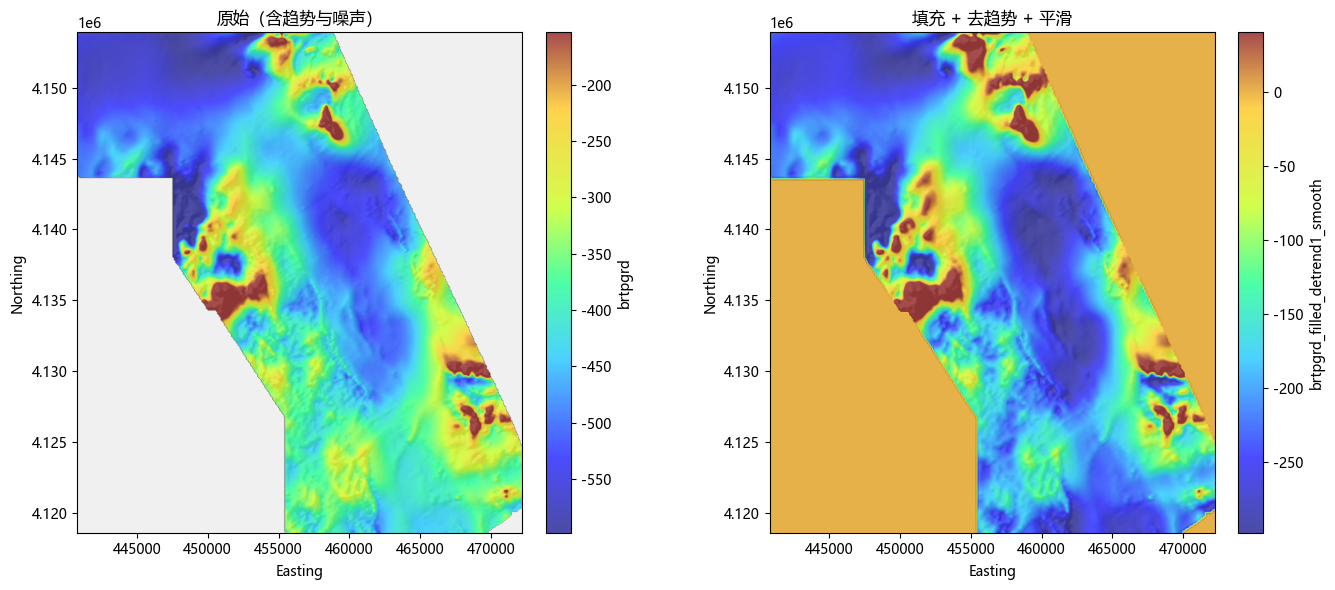

In [38]:
clean = g.fill_nodata().detrend(degree=1).smooth(deg=3, win=5)
clean.info()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
g.show(ax=axes[0], hs=True, colorbar=True, title='原始（含趋势与噪声）')
clean.show(ax=axes[1], hs=True, colorbar=True, title='填充 + 去趋势 + 平滑')
plt.tight_layout()


---

## 5. 方向导数

### 5.1 数学定义

对于标量场 $T(x,y)$，水平方向导数定义为：

$$
\frac{\partial T}{\partial x}, \quad \frac{\partial T}{\partial y}
$$

混合导数：

$$
\frac{\partial^2 T}{\partial x \partial y}
$$

### 5.2 三种计算算法

| 方法 | 原理 | 特点 |
| --- | --- | --- |
| **Savitzky-Golay (SG)** | 滑动窗口内多项式拟合，对拟合多项式求导 | 抗噪好，最常用 |
| **Finite-Sample (FS)** | 在窗口边缘做 tapering，中心做差分 | 边界更锐，但放大噪声 |
| **Fourier** | 频域乘 $i k_x$、$i k_y$ | 理论严格，但受边缘效应影响 |

### 5.3 物理意义

- $\partial T/\partial x$：磁场沿东西方向的变化率。正值表示向东磁场升高，负值表示降低。
- 导数图把"缓变的大异常"变成"沿异常边界的陡变带"，**边界被突出**。
- 二阶导数 $\partial^2 T/\partial x^2$ 更激进，只保留最高频、最浅的异常。

### 5.4 结果解读要点

- 导数图上"零交叉线"通常对应地质体边界。
- 导数幅值与异常埋深成反比：浅部异常导数大，深部异常导数小。


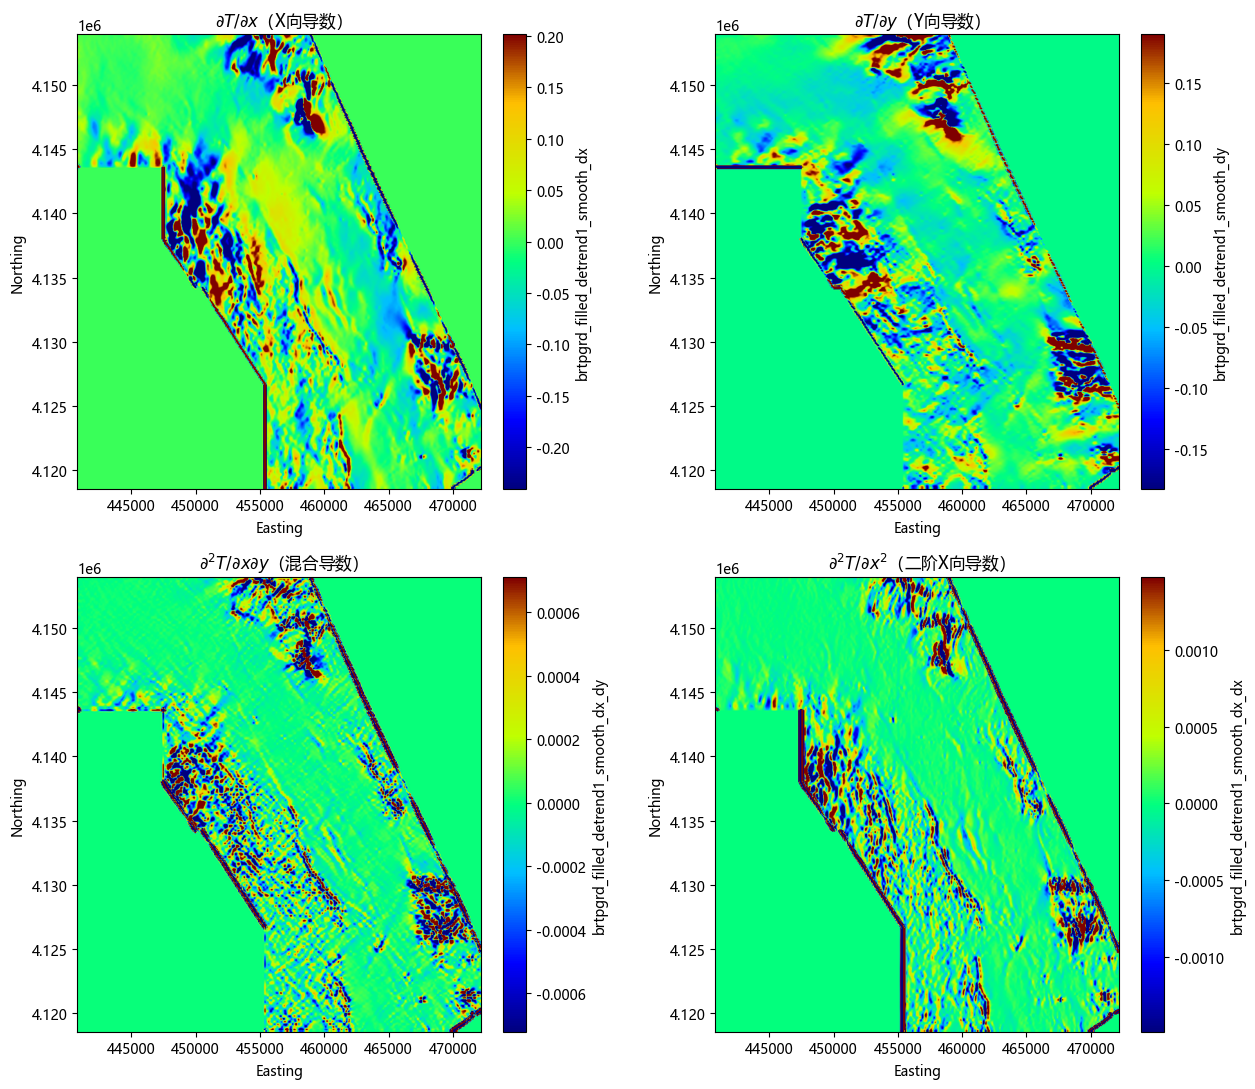

In [39]:
dx = clean.dx(method='SG')
dy = clean.dy(method='SG')
dxdy = clean.dxdy(method='SG')
dx2 = clean.dx2(method='SG')

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, gg, t in zip(axes.ravel(),
                     [dx, dy, dxdy, dx2],
                     ['$\\partial T / \\partial x$（X向导数）',
                      '$\\partial T / \\partial y$（Y向导数）',
                      '$\\partial^2 T / \\partial x \\partial y$（混合导数）',
                      '$\\partial^2 T / \\partial x^2$（二阶X向导数）']):
    gg.show(ax=ax, hs=False, colorbar=True)
    ax.set_title(t)
plt.tight_layout()


---

## 6. 垂直导数

### 6.1 为什么需要垂直导数？

磁异常是在**地表（或航高）**测得的，但场源在地下。垂直导数 $\partial T/\partial z$ 描述场随深度的变化率，它：
- 突出浅部高频异常
- 压制深部区域场
- 是计算总梯度、解析信号等边界识别算子的基础

### 6.2 两种算法

**Fourier 法（频率域）**：

在位场满足拉普拉斯方程 $\nabla^2 T = 0$ 的假设下，频率域乘子为 $|\mathbf{k}|$：

$$
\mathcal{F}\left[\frac{\partial T}{\partial z}\right] = |\mathbf{k}| \cdot \mathcal{F}[T]
$$

其中 $|\mathbf{k}| = 2\pi\sqrt{k_x^2 + k_y^2} / \Delta x$。

**ISVD 法（等效源/ISVD）**：

不直接在频域求导，而是先算水平导数 $\partial T/\partial x, \partial T/\partial y$，再利用拉普拉斯方程：

$$
\frac{\partial^2 T}{\partial z^2} = -\left(\frac{\partial^2 T}{\partial x^2} + \frac{\partial^2 T}{\partial y^2}\right)
$$

对其积分一次得到 $\partial T/\partial z$。优点是**抗噪更好**，因为水平导数用 SG 方法已经做了平滑。

### 6.3 一阶 vs 二阶

- 一阶 $\partial T/\partial z$：突出浅部异常
- 二阶 $\partial^2 T/\partial z^2$：更激进，只保留最浅、最锐的异常，常用于小构造识别


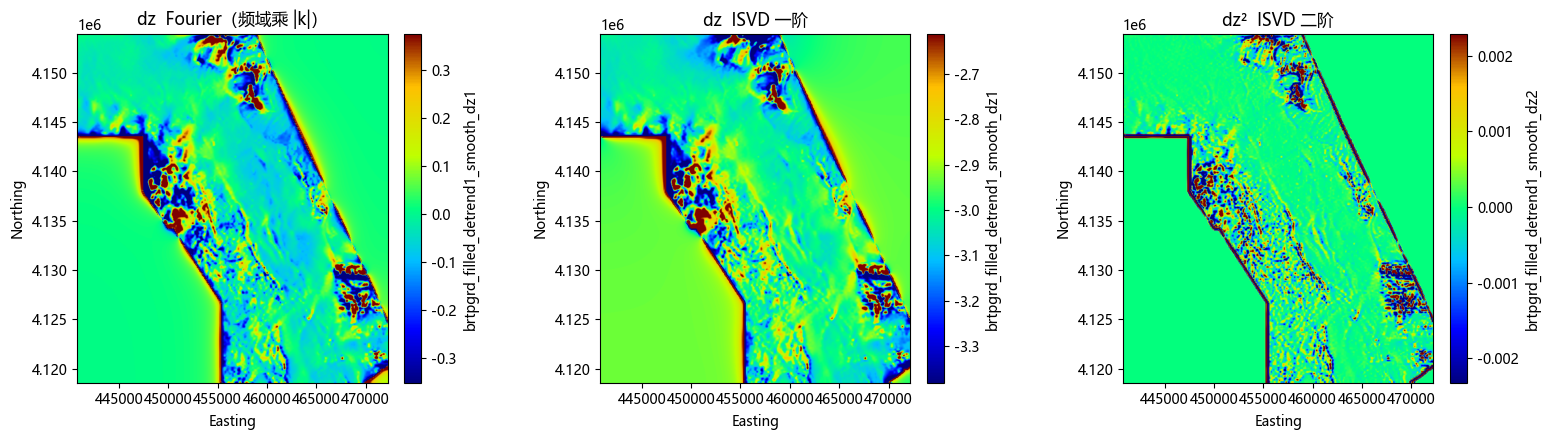

In [40]:
dz_fourier = clean.dz(method='fourier', order=1)
dz_isvd = clean.isvd(method='SG', order=1)
dz2_isvd = clean.isvd(method='SG', order=2)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, gg, t in zip(axes.ravel(),
                     [dz_fourier, dz_isvd, dz2_isvd],
                     ['dz  Fourier（频域乘 |k|）',
                      'dz  ISVD 一阶',
                      'dz²  ISVD 二阶']):
    gg.show(ax=ax, hs=False, colorbar=True)
    ax.set_title(t)
plt.tight_layout()


---

## 7. 垂直积分（Vertical Integration）

### 7.1 定义

垂直积分是垂直导数的逆运算，在频域除以 $|\mathbf{k}|$：

$$
\mathcal{F}\left[\int T\\,dz\right] = \frac{1}{|\mathbf{k}|} \cdot \mathcal{F}[T]
$$

### 7.2 作用

- 把浅部小异常**积分成宽缓的大异常**
- 突出深部、大尺度地质体
- 与垂直导数互补：导数看浅，积分看深

### 7.3 什么时候用

当你怀疑数据中"浅部噪声盖过了深部异常"时，可以做一次垂直积分，让深部构造显现出来。


<Axes: title={'center': '垂直积分 VI（突出深部异常）'}, xlabel='Easting', ylabel='Northing'>

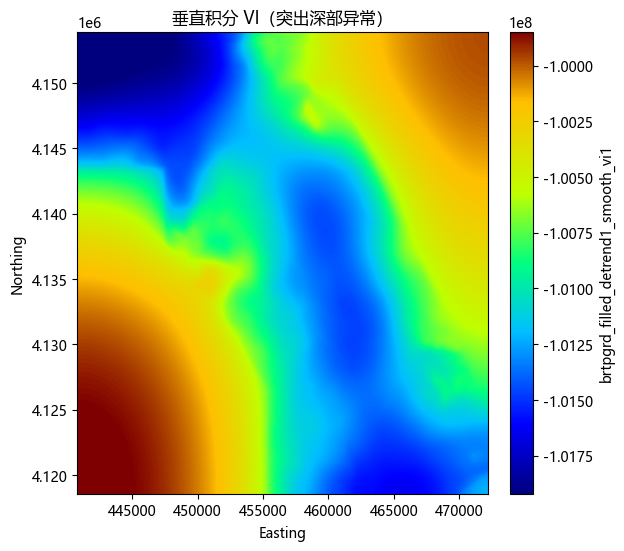

In [41]:
vi1 = clean.vi(order=1)
fig, ax = plt.subplots(figsize=(7, 6))
vi1.show(ax=ax, hs=False, colorbar=True, title='垂直积分 VI（突出深部异常）')


---

## 8. 边界识别算子（重点）

这是位场解释中最常用的一组工具，目标是：**在磁异常图上圈出地质体的边界**。

### 8.1 HGM（Horizontal Gradient Magnitude，水平梯度模）

$$
\text{HGM} = \sqrt{\left(\frac{\partial T}{\partial x}\right)^2 + \left(\frac{\partial T}{\partial y}\right)^2}
$$

- 就是水平方向导数的模
- 异常边界处磁场变化最陡 → HGM 出现峰值
- 最简单、最常用的边界识别指标

### 8.2 Tilt（倾斜角）

$$
\theta = \arctan\left(\frac{\partial T / \partial z}{\text{HGM}}\right)
$$

- 分子是垂直导数，分母是水平梯度
- **归一化**了异常幅值：弱异常和强异常都能显示
- 零值线（θ=0）对应地质体边界
- 范围 -90° ~ +90°

### 8.3 TG（Total Gradient / Analytic Signal，总梯度/解析信号振幅）

$$
A(x,y) = \sqrt{\left(\frac{\partial T}{\partial x}\right)^2 + \left(\frac{\partial T}{\partial y}\right)^2 + \left(\frac{\partial T}{\partial z}\right)^2}
$$

- 三维导数的模
- **峰值位置直接对应场源（球体/岩脉）的平面中心**
- 对斜磁化不敏感，是磁法解释的主力

### 8.4 LW（Local Wavenumber，局部波数）

$$
k(x,y) = \frac{\partial}{\partial x}\arctan\left(\frac{\partial T/\partial z}{\partial T/\partial x}\right)
$$

- 峰值位置对应场源中心
- 可用于**估算场源深度**（倾斜薄板的峰值宽度与深度成正比）

### 8.5 TAHG（Tilt Angle of the Horizontal Gradient）

对 HGM 再做一次 Tilt：

$$
\text{TAHG} = \arctan\left(\frac{\partial(\text{HGM})/\partial z}{\text{HGM}}\right)
$$

- 进一步锐化边界
- 边界定位比 HGM 更准


e:\venv\venv312\Lib\site-packages\interpies_lite\grid.py:264: RuntimeWarning: divide by zero encountered in divide
  out = np.arctan(alpha * dz_grid.data / hgm_grid.data) * 180.0 / np.pi


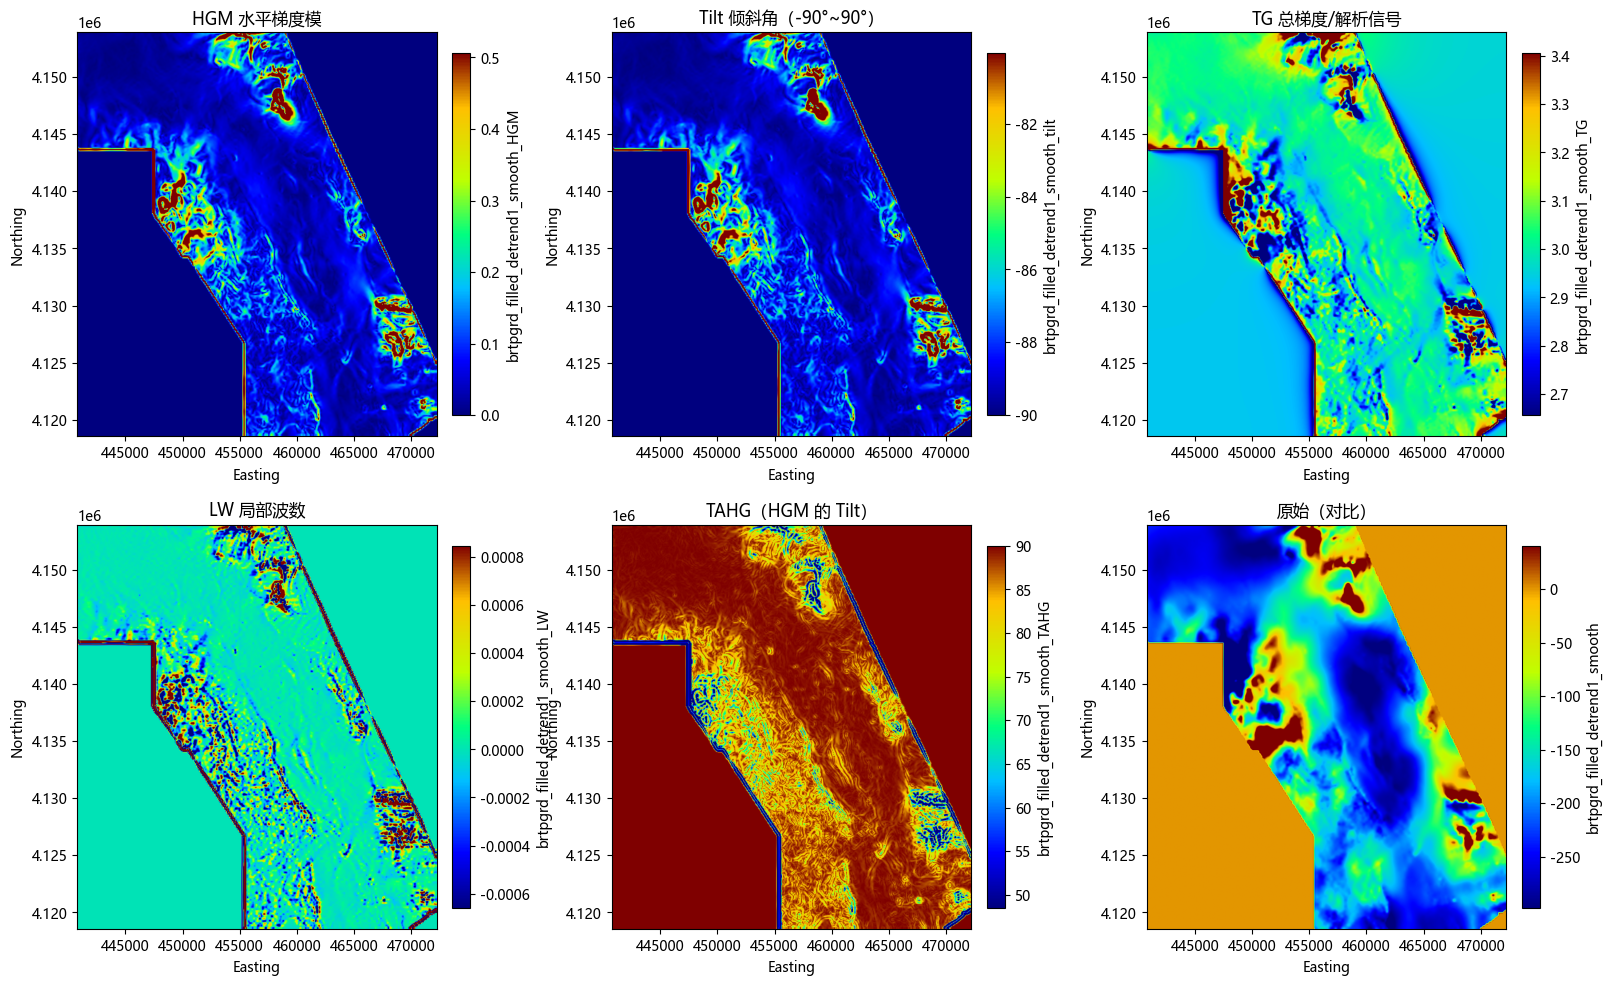

In [42]:
hgm = clean.hgm()
tilt = clean.tilt()
tg = clean.tg()
lw = clean.lw()
tahg = clean.tahg()

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
items = [(hgm, 'HGM 水平梯度模'),
         (tilt, 'Tilt 倾斜角（-90°~90°）'),
         (tg, 'TG 总梯度/解析信号'),
         (lw, 'LW 局部波数'),
         (tahg, 'TAHG（HGM 的 Tilt）'),
         (clean, '原始（对比）')]
for ax, (gg, t) in zip(axes.ravel(), items):
    gg.show(ax=ax, hs=False, colorbar=True)
    ax.set_title(t)
plt.tight_layout()


---

## 9. 向上延拓与区域-局部分离

### 9.1 什么是向上延拓？

位场延拓：假设我们在更高的高度 $z$ 处测量磁场，理论上可以通过数学变换把地表观测值"搬"到那个高度。

**向上延拓公式（频域）**：

$$
\mathcal{F}[T_{\text{up}}(z)] = e^{-|\mathbf{k}| \cdot z} \cdot \mathcal{F}[T]
$$

$e^{-|\mathbf{k}| z}$ 是一个低通滤波器：$|\mathbf{k}|$ 越大（高频/浅部异常）衰减越厉害。

### 9.2 物理效果

- **向上延拓 250 m**：浅部小异常被平滑掉，保留较大的区域异常
- **向上延拓 2000 m**：几乎只剩深部区域场

### 9.3 区域-局部分离（高通滤波）

$$
T_{\text{局部}} = T_{\text{原始}} - T_{\text{向上延拓}}
$$

- 向上延拓得到"区域场"
- 原始减区域 = "局部场"（浅部小异常）
- 这是磁法/重力法最经典的分解方法


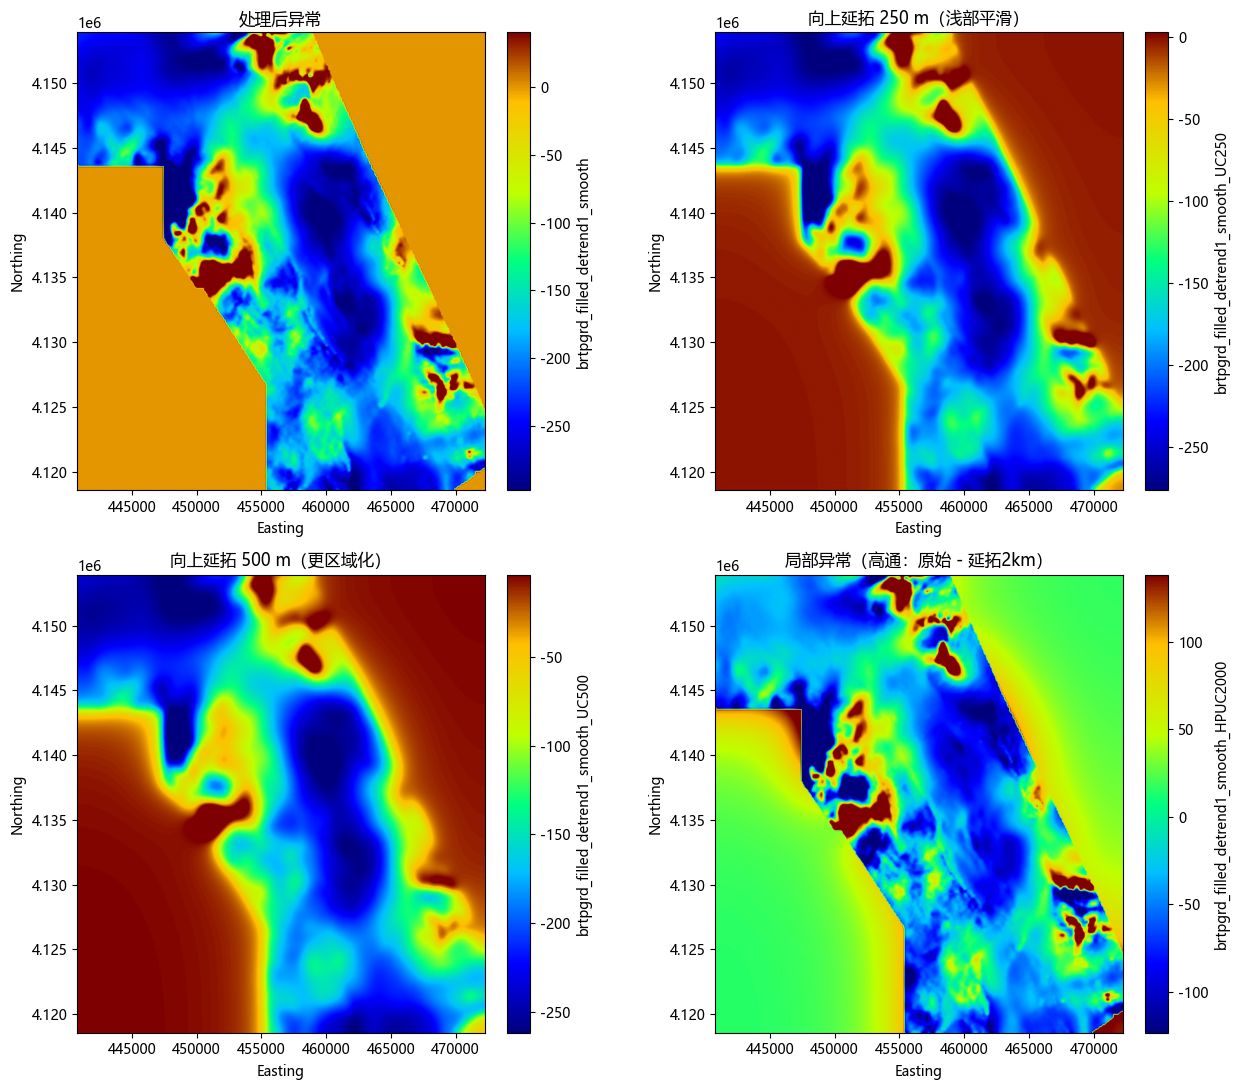

In [43]:
up250 = clean.up(z=250)
up500 = clean.up(z=500)
hp = clean.hp_filter_uc(z=2000)

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, gg, t in zip(axes.ravel(),
                     [clean, up250, up500, hp],
                     ['处理后异常',
                      '向上延拓 250 m（浅部平滑）',
                      '向上延拓 500 m（更区域化）',
                      '局部异常（高通：原始 - 延拓2km）']):
    gg.show(ax=ax, hs=False, colorbar=True)
    ax.set_title(t)
plt.tight_layout()


---

## 10. Laplacian 滤波

### 10.1 定义

$$
\nabla^2 T = \frac{\partial^2 T}{\partial x^2} + \frac{\partial^2 T}{\partial y^2}
$$

### 10.2 作用

- 二阶水平导数之和
- 突出最高频、最浅的异常
- 相当于"边缘增强"滤镜（类似 Photoshop 的 USM 锐化）
- 噪声敏感，通常先平滑再做 Laplacian


<Axes: title={'center': 'Laplacian 滤波（高频增强）'}, xlabel='Easting', ylabel='Northing'>

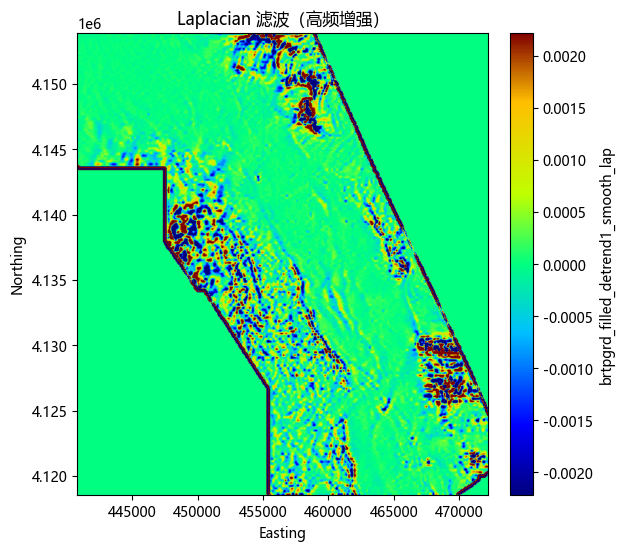

In [44]:
lap = clean.laplacian()
fig, ax = plt.subplots(figsize=(7, 6))
lap.show(ax=ax, hs=False, colorbar=True, title='Laplacian 滤波（高频增强）')


---

## 11. 结果保存

- `save(path)`：写出 GeoTIFF（带地理参考）
- `save_image(path)`：写出 PNG 图（无色标边框，可直接用于报告）


In [45]:
# 保存 Tilt 结果为 GeoTIFF
tilt.save('tilt_result.tif')
print('已保存: tilt_result.tif')

# 保存 HGM 结果为 PNG
hgm.save_image('hgm_result.png', dpi=150)
print('已保存: hgm_result.png')


已保存: tilt_result.tif
已保存: hgm_result.png


---

## 12. 完整处理流程（链式调用）

实际解释中，我们通常把以上步骤串成一条流水线：

```
原始数据
  → fill_nodata（填空区）
  → detrend（去区域趋势）
  → smooth（去噪声）
  → hp_filter_uc（分离局部异常）
  → tilt / tg（圈边界）
  → 成图解释
```

`interpies_lite` 中所有变换都返回新的 `Grid` 对象，可以一行串完：


e:\venv\venv312\Lib\site-packages\interpies_lite\transforms.py:42: RuntimeWarning: Mean of empty slice
  lambda v: np.nanmean(v),


<Axes: title={'center': '完整流水线：填充 → 去趋势 → 平滑 → 高通 → Tilt'}, xlabel='Easting', ylabel='Northing'>

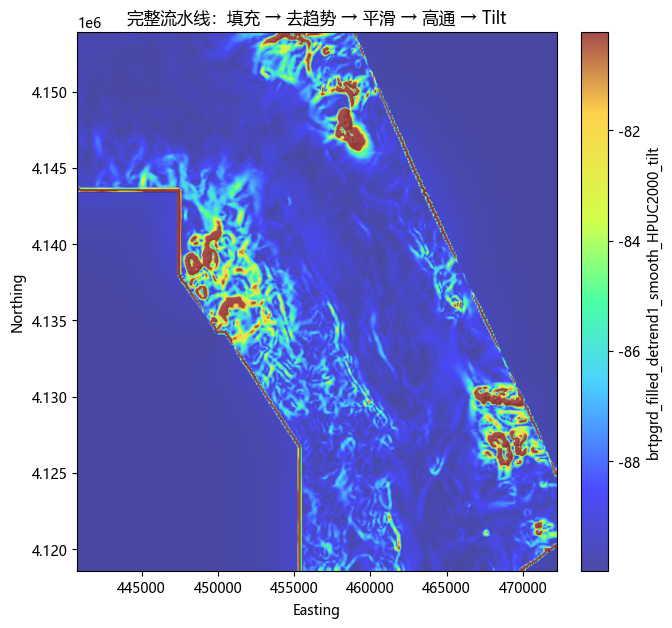

In [46]:
final = (
    g
    .fill_nodata()
    .detrend(degree=1)
    .smooth(win=5)
    .hp_filter_uc(z=2000)
    .tilt()
)
fig, ax = plt.subplots(figsize=(8, 7))
final.show(ax=ax, hs=True, colorbar=True,
           title='完整流水线：填充 → 去趋势 → 平滑 → 高通 → Tilt')


---

## 13. 本课小结

| 任务 | 用什么方法 | 看什么 |
| --- | --- | --- |
| 去趋势、去噪声 | `detrend` + `smooth` | 数据干净，异常形状清晰 |
| 突出浅部异常 | `dz`（垂直导数） | 高频细节 |
| 突出深部异常 | `vi`（垂直积分） | 宽缓大异常 |
| 圈定地质体边界 | `HGM` / `Tilt` / `TG` | 峰值/零交叉线位置 |
| 估算场源深度 | `LW`（局部波数） | 峰值宽度与深度关系 |
| 分离区域与局部 | `up` + `hp_filter_uc` | 区域场 vs 浅部异常 |
| 高频锐化 | `Laplacian` | 类似边缘增强滤镜 |

### 关键公式速查

- 水平梯度模：$\text{HGM} = \sqrt{T_x^2 + T_y^2}$
- 倾斜角：$\theta = \arctan(T_z / \text{HGM})$
- 总梯度：$A = \sqrt{T_x^2 + T_y^2 + T_z^2}$
- 向上延拓：$\mathcal{F}[T_{up}] = e^{-|\mathbf{k}| z}\mathcal{F}[T]$
- 拉普拉斯：$\nabla^2 T = T_{xx} + T_{yy} = -T_{zz}$

### 作业思考

1. 为什么 Tilt 角能让弱异常也显现出来？（提示：做了除法归一化）
2. 向上延拓为什么能"压制浅部异常"？（提示：$e^{-|\mathbf{k}| z}$ 对高频衰减快）
3. HGM 和 TG 的区别是什么？什么时候 TG 更有用？
